In [1]:
import numpy as np 
from sklearn import datasets
import torch.nn as nn
import torch
import os
from datetime import datetime
from sklearn.preprocessing import StandardScaler
import copy
import matplotlib.pyplot as plt

In [2]:
torch.set_default_dtype(torch.float64)

In [3]:
#Configs

SEED=42
OUTPUT_DIR=os.path.join(os.getcwd(),f"Optimiser_plots_{datetime.now().strftime('%Y%m%d_%H%M%S')}")


In [4]:
#function to get dataset
def make_moons(n_samples=600,noise=0.2,seed=SEED):
    X,y=datasets.make_moons(n_samples=n_samples,noise=noise,random_state=seed)
    X=StandardScaler().fit_transform(X)
    return torch.from_numpy(X),torch.from_numpy(y.astype(np.float64)).unsqueeze(1) #(numsamples,dim) (numsamples,1)


In [5]:
#function to make model 
def make_model(seed=SEED):
    torch.manual_seed(seed)

    return nn.Sequential(
        nn.Linear(2,32),nn.Tanh(),
        nn.Linear(32,32),nn.Tanh(),
        nn.Linear(32,1)
    )

In [6]:
loss_fn=nn.BCEWithLogitsLoss()

In [7]:
#base class for all optimisers
class Optimizer():
    def __init__(self,params,lr) -> None:
        self.params=list(params) #materalise generator (model.parameters())
        self.lr=lr
        self.state=[{} for _ in self.params] # one state dict per parameter
        self.t=0 #timestep ( used in adam bias correction)

    def zero_grad(self):
        for p in self.params:
            p.grad=None

    @torch.no_grad()
    def step(self):
        self.t +=1
        for p ,state in zip(self.params,self.state):
            if p.grad is None:
                continue
            self._update(p,p.grad,state)

    def _update(self,p,g,state):
        raise NotImplementedError

In [8]:
#optimizer classes
#SGD  
# theta <- theta - lr * g
class SGD(Optimizer):
    def __init__(self,params,lr=0.01,weight_decay=0.0):
        super().__init__(params,lr)
        self.weight_decay=weight_decay

    def _update(self,p,g,state):
        if self.weight_decay!=0.0:
            g = g + self.weight_decay *p
        p -= self.lr * g


#SGD with momentum
#     v     <- mu * v + g  (velocity = running sum of past gradients)
#     theta <- theta - lr * v
# low, consistent gradients that keep pointing the same way add up (faster), alternating gradients( flip
# sign) cancel out (less zig-zag). mu = 0.9 ~ the last 1/(1-mu) = 10 gradients .
class SGDMomentum(Optimizer):
        def __init__(self,params,lr=0.01,weight_decay=0.0,momentum=0.9):
            super().__init__(params,lr)
            self.momentum=momentum
            self.weight_decay=weight_decay

        def _update(self,p,g,state):
            if self.weight_decay!=0.0:
                g = g + self.weight_decay *p
            v= state.get('v',torch.zeros_like(p))  #velocity init at 0
            v=self.momentum*v + g
            state['v']=v

            p -= self.lr*v

#RMSprop
#     s     <- alpha * s + (1 - alpha) * g^2        (EMA of squared gradients)
#     theta <- theta - lr * g / (sqrt(s) + eps)
# Divides each coordinate by the RMS of its recent gradients -> per-parameter
# adaptive learning rate. Steep directions (large |g|) get damped, flat directions
# get boosted. alpha = 0.99 averages over roughly the last 100 steps.
class RMSProp(Optimizer):
        def __init__(self,params,lr=0.01,weight_decay=0.0,alpha=0.99,eps=1e-8):
            super().__init__(params,lr)
            self.alpha=alpha
            self.weight_decay=weight_decay
            self.eps=eps

        def _update(self,p,g,state):
            if self.weight_decay!=0.0:
                g = g + self.weight_decay *p
            s= state.get('s',torch.zeros_like(p))  #velocity init at 0
            s=self.alpha*s + (1-self.alpha) *g *g
            state['s']=s

            p -= self.lr*g/(s.sqrt() + self.eps)  

#RMSprop with momentum
#     s     <- alpha * s + (1 - alpha) * g^2
#     b     <- mu * b + g / (sqrt(s) + eps)         (momentum on the *normalised* gradients, unlike adam which normalizes momentum)
#     theta <- theta - lr * b
# Same as RMSprop, but instead of applying the normalised gradient directly we
# accumulate it in a velocity buffer, exactly like SGD momentum does with raw g
class RMSPropMomentum(Optimizer):
        def __init__(self,params,lr=0.01,weight_decay=0.0,alpha=0.99,eps=1e-8,momentum=0.9):
            super().__init__(params,lr)
            self.alpha=alpha
            self.weight_decay=weight_decay
            self.eps=eps
            self.momentum=momentum

        def _update(self,p,g,state):
            if self.weight_decay!=0.0:
                g = g + self.weight_decay *p
            s= state.get('s',torch.zeros_like(p))  #velocity init at 0
            s=self.alpha*s + (1-self.alpha) *g *g
            state['s']=s

            b=state.get('b',torch.zeros_like(p))
            b=self.momentum * b + g /(s.sqrt() + self.eps)
            state['b']=b

            p -= self.lr*b

# Adam  (Adaptive Moments) = momentum (1st moment) + RMSprop (2nd moment) + bias correction
#     m     <- beta1 * m + (1 - beta1) * g          (EMA of gradients      -> direction)
#     v     <- beta2 * v + (1 - beta2) * g^2        (EMA of squared grads  -> scale)
#     m_hat  = m / (1 - beta1^t)                    (bias correction: m, v start at 0,
#     v_hat  = v / (1 - beta2^t)                     so early EMAs are biased toward 0)
#     theta <- theta - lr * m_hat / (sqrt(v_hat) + eps)
#
# weight_decay here is the *classic L2* version: wd * theta is added to the gradient
# BEFORE the moments. This means the decay term also gets divided by sqrt(v_hat),
# so parameters with large gradients are barely regularised. In short Regularization doesnt effect each parameter the same.
class Adam(Optimizer):
        def __init__(self,params,lr=0.001,betas=(0.9,0.999),eps=1e-8,weight_decay=0.0):
            super().__init__(params,lr)
            self.beta1,self.beta2=betas
            self.weight_decay=weight_decay
            self.eps=eps

        def _update(self,p,g,state):
            if self.weight_decay!=0.0:
                g = g + self.weight_decay *p #L2 penalty couple with gradients

            m=state.get('m',torch.zeros_like(p))
            m=self.beta1*m + (1-self.beta1)* g
            v=state.get('v',torch.zeros_like(p))
            v=self.beta2*v + (1-self.beta2)*g*g
            state['m'],state['v']=m,v

            m_hat= m/(1-self.beta1**self.t)
            v_hat=v/(1-self.beta2**self.t)

            p -= self.lr * m_hat /(v_hat.sqrt()+self.eps)



class AdamW(Optimizer):
        def __init__(self,params,lr=0.001,betas=(0.9,0.999),eps=1e-8,weight_decay=0.0):
            super().__init__(params,lr)
            self.beta1,self.beta2=betas
            self.weight_decay=weight_decay
            self.eps=eps

        def _update(self,p,g,state):

            #decoupled weight decay ( the only difference from ADAM)
            p *= 1 - self.lr*self.weight_decay

            #same as ADAM
            m=state.get('m',torch.zeros_like(p))
            m=self.beta1*m + (1-self.beta1)* g
            v=state.get('v',torch.zeros_like(p))
            v=self.beta2*v + (1-self.beta2)*g*g
            state['m'],state['v']=m,v

            m_hat= m/(1-self.beta1**self.t)
            v_hat=v/(1-self.beta2**self.t)

            p -= self.lr * m_hat /(v_hat.sqrt()+self.eps)





In [9]:
#part1  to compare scratch optimisers with torch.optim

def compare_with_torch(my_opt_fn,torch_opt_fn,steps=100,batch_size=32,tol=1e-10):

    X,y=make_moons()

    model_mine=make_model()
    model_ref=copy.deepcopy(model_mine)  #identical starting weights

    opt_mine=my_opt_fn(model_mine.parameters())
    opt_ref=torch_opt_fn(model_ref.parameters())

    #batch indices
    gen=torch.Generator().manual_seed(SEED)
    batches = [torch.randint(0,len(X),(batch_size,),generator=gen) for _ in range(steps)]

    max_dif=0.0
    for idx in batches:
        for model, opt in ((model_mine,opt_mine),(model_ref,opt_ref)):
            opt.zero_grad()
            loss=loss_fn(model(X[idx]),y[idx])
            loss.backward()
            opt.step()

        step_diff=max((pm-pr).abs().max().item()  for pm, pr in zip(model_mine.parameters(),model_ref.parameters()))
        max_dif=max(max_dif,step_diff)
    return max_dif ,max_dif<tol

def run_verification():
    print("~" *50)
    print(" my optimisers vs torch.optim  (tr len 100 steps, dtype float64)")
    print("~" * 50)

    # tuple ---> (name, our optimiser, matching torch.optim optimiser)| weight decay to be seen with lr*wd.
    cases = [
            ("SGD",
             lambda p: SGD(p, lr=0.1), #small grad , so large lr
             lambda p: torch.optim.SGD(p, lr=0.1)),
            ("SGD + weight decay",
             lambda p: SGD(p, lr=0.1, weight_decay=1e-2),
             lambda p: torch.optim.SGD(p, lr=0.1, weight_decay=1e-2)),
            ("SGD momentum",
             lambda p: SGDMomentum(p, lr=0.05, momentum=0.9), #half as sgd , momentum make steps 1/(1-0.9) ~ 10x 
             lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9)),
            ("RMSprop",
             lambda p: RMSProp(p, lr=0.01, alpha=0.99, eps=1e-8),# 100 steps only so 0.01 so steps move more, def is 0.001
             lambda p: torch.optim.RMSprop(p, lr=0.01, alpha=0.99, eps=1e-8)),
            ("RMSprop + momentum",
             lambda p: RMSPropMomentum(p, lr=0.005, alpha=0.99, eps=1e-8, momentum=0.9),#half as rmsprop , same reason as in sgd plus momentum
             lambda p: torch.optim.RMSprop(p, lr=0.005, alpha=0.99, eps=1e-8, momentum=0.9)),
            ("Adam",
             lambda p: Adam(p, lr=0.01, betas=(0.9, 0.999), eps=1e-8), # 100 steps only so 0.01 so steps move more, def is 0.001
             lambda p: torch.optim.Adam(p, lr=0.01, betas=(0.9, 0.999), eps=1e-8)),
            ("Adam + L2 weight decay",
             lambda p: Adam(p, lr=0.01, weight_decay=0.1),
             lambda p: torch.optim.Adam(p, lr=0.01, weight_decay=0.1)),
            ("AdamW",
             lambda p: AdamW(p, lr=0.01, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.1),
             lambda p: torch.optim.AdamW(p, lr=0.01, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.1)),
        ]
    all_ok=True
    for name,mine,ref in cases:
        max_diff,ok=compare_with_torch(mine,ref)
        all_ok &= ok
        print(f"  {name:<26} max |theta_mine - theta_torch| = {max_diff:.2e}   "
              f"{'PASS' if ok else 'FAIL'}")
        
    #Adam with weight decay and ADAMW are different algos, sanity check .
    max_diff,ok=compare_with_torch(
        lambda p:Adam(p,lr=0.01,weight_decay=0.1),
        lambda p: torch.optim.AdamW(p,lr=0.01,weight_decay=0.1)
    )
    print(f"\n  Sanity check - my Adam(wd) vs torch AdamW (should not be same): "
          f"max diff = {max_diff:.2e}  -> {'differ, as expected' if not ok else 'UNEXPECTED MATCH'}")
    print(f"\n  All optimisers match torch.optim: {all_ok}\n")  
    return all_ok

In [ ]:
#part2 compare optimisers with each other  on MLP 2→32→32→1
#1185 parameters , 600 points > heavily overparamterized
#batch 32 gives 19 update steps per epoch, so over 60 epochs ~1140 steps
#mini batch training ,returns full dataset loss after each epoch, the final l2 norm of weights and the accuracy 

def train(opt_fn,X,y,epochs=60,batch_size=32):

    model=make_model()
    opt=opt_fn(model.parameters())
    gen=torch.Generator().manual_seed(SEED)  #same batch order for all optimizers

    def full_loss():
        with torch.no_grad():
            return loss_fn(model(X),y).item()
    losses=[full_loss()]  #initial loss

    for _ in range(epochs):
        perm = torch.randperm(len(X),generator=gen)
        for i in range(0,len(X),batch_size):
            idx=perm[i:i+batch_size] 
            opt.zero_grad()
            loss_fn(model(X[idx]),y[idx]).backward()
            opt.step()
        losses.append(full_loss())  
    with torch.no_grad():
        acc=((model(X)>0).double() == y).double().mean().item()
        w_norm= torch.sqrt(sum((p**2).sum ()for p in model.parameters())).item()
    return losses,acc,w_norm


#commonly used learning rates
# Plain SGD needs a much larger lr than the adaptive methods, because RMSprop and
# Adam divide by sqrt(E[g^2] i.e v) so their  max step size is ~lr regardless of |g|.
TUNED = {
    "SGD":               lambda p: SGD(p, lr=0.5),
    "SGD momentum":      lambda p: SGDMomentum(p, lr=0.05, momentum=0.9),
    "RMSprop":           lambda p: RMSProp(p, lr=0.005),
    "RMSprop + momentum": lambda p: RMSPropMomentum(p, lr=0.001, momentum=0.9),
    "Adam":              lambda p: Adam(p, lr=0.005),
    "AdamW":             lambda p: AdamW(p, lr=0.005, weight_decay=0.1),
}

# The same lr for all of them -> shows how differently each rule scales a step.
SAME_LR = 0.01
SAME = {
    "SGD":               lambda p: SGD(p, lr=SAME_LR),
    "SGD momentum":      lambda p: SGDMomentum(p, lr=SAME_LR, momentum=0.9),
    "RMSprop":           lambda p: RMSProp(p, lr=SAME_LR),
    "RMSprop + momentum": lambda p: RMSPropMomentum(p, lr=SAME_LR, momentum=0.9),
    "Adam":              lambda p: Adam(p, lr=SAME_LR),
    "AdamW":             lambda p: AdamW(p, lr=SAME_LR, weight_decay=0.1),
}

COLORS = {
    "SGD": "tab:blue", "SGD momentum": "tab:orange", "RMSprop": "tab:green",
    "RMSprop + momentum": "tab:red", "Adam": "tab:purple", "AdamW": "tab:brown",
}

def run_mlp_comparison():
    print("~" * 50)
    print(" MLP on 'two moons' (600 points, batch 32) for across optimisers comparison")
    print("~" * 50)
    X, y = make_moons()

    fig,axes=plt.subplots(1,3,figsize=(18,5))
    axes[0].scatter(X[:,0],X[:,1],c=y.squeeze(),cmap='coolwarm',s=10)
    axes[0].set_title('make moons dataset')

    for ax, (title,configs) in zip(axes[1:],[('tune lr per optimiser',TUNED),(f'same lr {SAME_LR} per optimiser',SAME)]):
        print(f' \n {title}')
        print(f"  {'optimiser':<20}{'final loss':>12}{'accuracy':>11}{'||theta||':>11}")
        for name,opt_fn in configs.items():
            losses,acc,w_norm=train(opt_fn,X,y)
            ax.plot(losses,label=name,color=COLORS[name])
            print(f"  {name:<20}{losses[-1]:>12.4f}{acc:>11.3f}{w_norm:>11.2f}")
        ax.set_yscale("log")
        ax.set_xlabel("epoch")
        ax.set_ylabel("training loss (BCE, log scale)")
        ax.set_title(title)
        ax.grid(alpha=0.3)
        ax.legend()
    print("\n  Note: ||theta|| is the L2 norm of all weights. AdamW's decoupled weight decay")
    print("  keeps it smaller than Adam's, which is the regularisation effect we want.\n")

    fig.tight_layout()
    path=os.path.join(OUTPUT_DIR,'mlp_loss_curve.png')
    fig.savefig(path,dpi=120)
    print(f"  saved -> {path}\n")


In [11]:
#part3 trajectory on ill conditoned 2D quadratic 
# f(x, y) = 0.1 * x^2 + 2 * y^2
# The curvature along y is 20x the curvature along x: a long, narrow valley.
#   - A lr large enough to move quickly along x makes y oscillate / diverge.
#   - A lr small enough for y makes progress along x painfully slow.
# That trade-off is exactly what momentum and adaptive methods address.

def f2d(w):
    return 0.1 * w[0] ** 2 + 2.0  * w[1] ** 2

def trajectory(opt_fn,start=(-5.0,-2.0),steps=50):
    w=torch.tensor(start,requires_grad=True)
    opt=opt_fn([w])
    path= [w.detach().clone().numpy()]

    for _ in range(steps):
        opt.zero_grad()
        f2d(w).backward()
        opt.step()
        path.append(w.detach().clone().numpy())
    return np.array(path),opt

TRAJ = {
    "SGD":               lambda p: SGD(p, lr=0.4),
    "SGD momentum":      lambda p: SGDMomentum(p, lr=0.1, momentum=0.7),
    "RMSprop":           lambda p: RMSProp(p, lr=0.3, alpha=0.9),
    "RMSprop + momentum": lambda p: RMSPropMomentum(p, lr=0.05, alpha=0.9, momentum=0.8),
    "Adam":              lambda p: Adam(p, lr=0.5),
    "AdamW":             lambda p: AdamW(p, lr=0.5, weight_decay=0.1),
}

def run2Dcomparison():
    print("~" * 50)
    print("minimising f(x, y) = 0.1 x^2 + 2 y^2 from (-5, -2), 50 steps")
    print("~" * 50)

    xs,ys=np.meshgrid(np.linspace(-5.5,2,200),np.linspace(-3,3,200))
    zs= 0.1 *xs ** 2 + 2 * ys**2

    fig,axes=plt.subplots(2,3,figsize=(16,9))
    for ax,(name,opt_fn) in zip(axes.flat,TRAJ.items()):
        path,opt=trajectory(opt_fn)
        final_f=f2d(torch.tensor(path[-1])).item()
        print(f"  {name:<20} final point = ({path[-1, 0]:+.4f}, {path[-1, 1]:+.4f})"
              f"   f = {final_f:.2e}")

        ax.contour(xs,ys,zs,levels=25,cmap='Greys',alpha=0.6)
        ax.plot(path[:,0],path[:,1],"o-",ms=3,color=COLORS[name])
        ax.plot(0,0,'k*',ms=12)
        ax.set_title(f' {name} lr {opt.lr} (final f = {final_f:.1e})')
        ax.set_xlim(-5.5,2)
        ax.set_ylim(-3,3)

    fig.suptitle("Optimiser trajectories on f(x, y) = 0.1x² + 2y²   (star = minimum)")
    fig.tight_layout()
    path=os.path.join(OUTPUT_DIR,"trajectories_2d.png")
    fig.savefig(path,dpi=120)
    print(f"\n  saved -> {path}\n")






~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 my optimisers vs torch.optim  (tr len 100 steps, dtype float64)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  SGD                        max |theta_mine - theta_torch| = 2.78e-16   PASS
  SGD + weight decay         max |theta_mine - theta_torch| = 1.11e-16   PASS
  SGD momentum               max |theta_mine - theta_torch| = 1.67e-16   PASS
  RMSprop                    max |theta_mine - theta_torch| = 0.00e+00   PASS
  RMSprop + momentum         max |theta_mine - theta_torch| = 1.90e-12   PASS
  Adam                       max |theta_mine - theta_torch| = 5.55e-16   PASS
  Adam + L2 weight decay     max |theta_mine - theta_torch| = 1.67e-16   PASS
  AdamW                      max |theta_mine - theta_torch| = 2.22e-16   PASS

  Sanity check - my Adam(wd) vs torch AdamW (should not be same): max diff = 1.36e+00  -> differ, as expected

  All optimisers match torch.optim: True

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 MLP

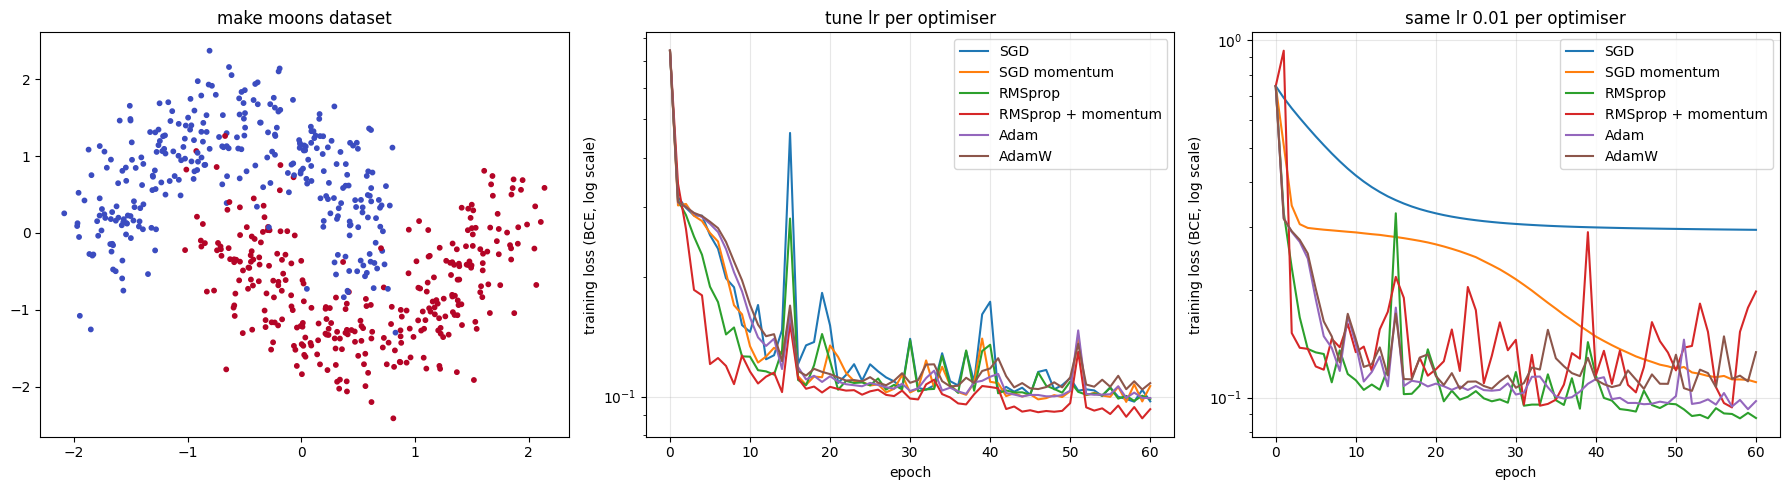

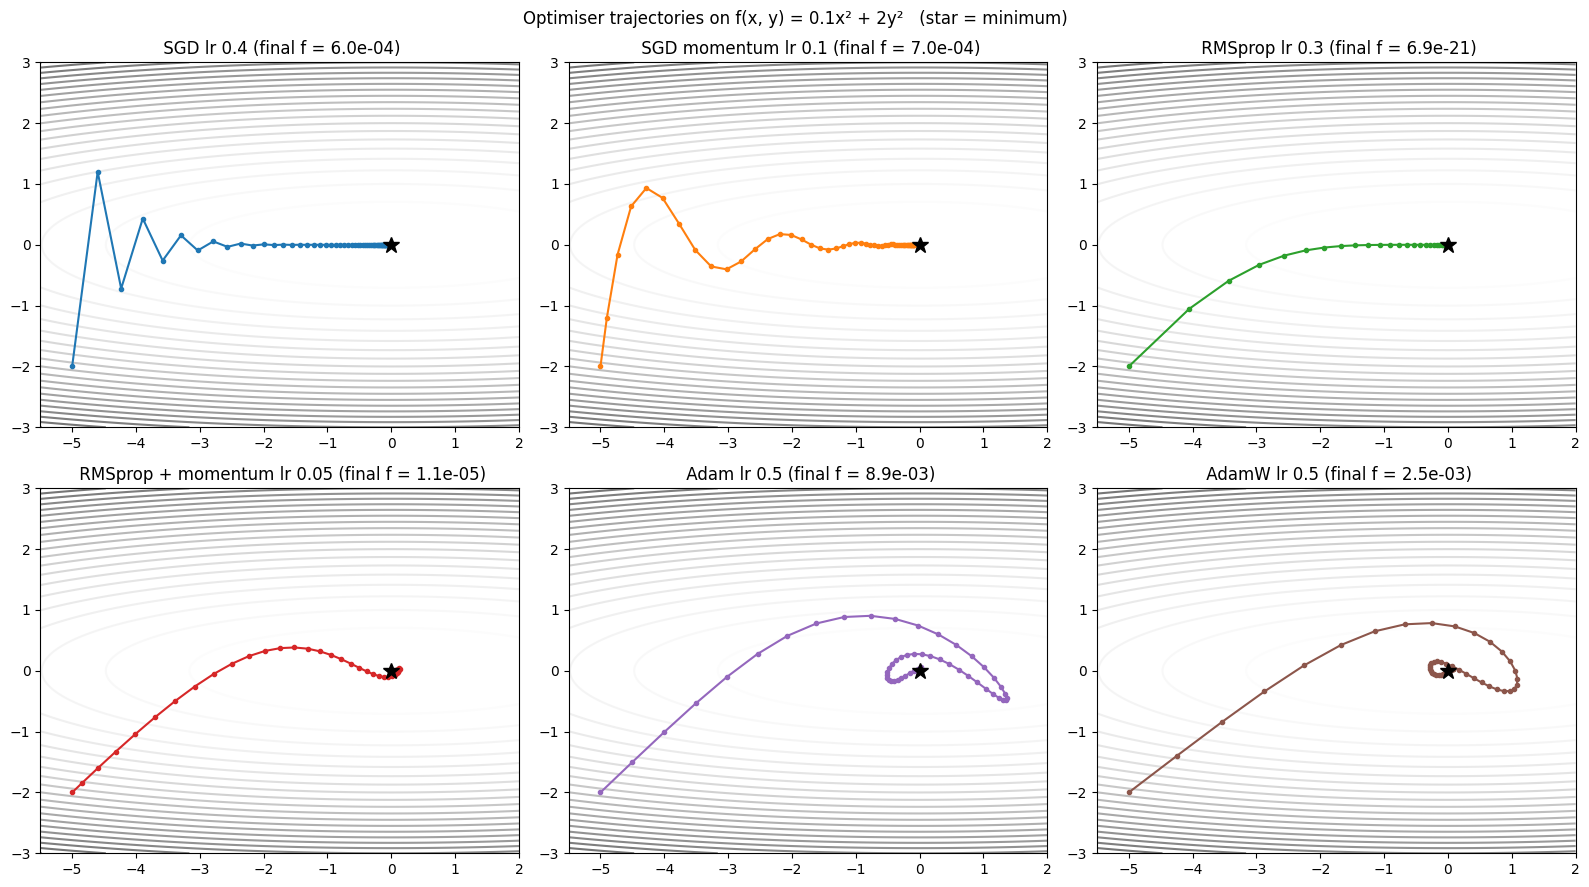

In [12]:
if __name__ == "__main__":
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    run_verification()
    run_mlp_comparison()
    run2Dcomparison()

    plt.show()

Interpretations (claude used):
### Part 1 — correctness check against `torch.optim`

**What is measured.** The maximum elementwise difference `|θ_mine − θ_torch|`, taken over
every parameter scalar and over all 100 steps — not the loss, and not just the final point. Two different update rules can produce similar losses by coincidence; they cannot agree scalar-by-scalar for 100 consecutive steps from identical initial weights and identical batch indices.

**Result.** Seven of eight optimisers agree to `1e-16`, i.e. ~1 unit in the last place of float64 (ε ≈ 2.22e-16). This is the strongest statement available: the implementations differ only in floating-point operation order, not in the update rule. Setting `torch.set_default_dtype(torch.float64)` is what makes the test meaningful — in float32 (ε ≈ 1.2e-7) a `1e-10` tolerance is unreachable and the test would be vacuous.

**RMSprop = `0.00e+00`** is bitwise identity: the expression order happens to match the torch kernel exactly. This is op-ordering luck, not a stronger correctness guarantee.

**RMSprop + momentum = `1.90e-12`** is four orders looser, and this is the expected behaviour rather than a defect. It is the deepest composition in the set(`s → sqrt(s)+eps → g/(sqrt(s)+eps) → b`), and round-off entering `s` is fed into a recursive velocity buffer whose geometric memory amplifies perturbations by roughly `1/(1-μ) = 10`. Drift from 1e-16 to 1e-12 over 100 steps is amplified round-off; a real
formula error would appear at order `lr·|g| ≈ 1e-3`.

**Why `tol = 1e-10`.** It sits in the empty band between float64 noise (1e-16 … 1e-12) and the smallest plausible algorithmic disagreement (≥ 1e-4).

**The sanity check is the load-bearing line.** Eight PASSes are also what a broken,insensitive test prints. Comparing my `Adam(weight_decay=0.1)` against`torch.optim.AdamW(weight_decay=0.1)` gives `max diff = 1.36e+00`, proving the harness can detect a real difference when one exists.

**Why those two differ.** Adam's L2 adds `λ·θ` to the gradient *before* the moments, so the penalty is then divided by `sqrt(v̂)` — effective shrinkage becomes `lr·λ·θ_i / sqrt(v̂_i)`,so coordinates with large gradient history are barely regularised and regularisation
strength is coupled to gradient scale. AdamW applies `θ ← θ(1 − lr·λ)` outside the adaptive rescaling, shrinking every coordinate by the same multiplicative factor.

**Note on SGD.** For plain SGD the two schemes are algebraically identical:`θ − lr(g + λθ) = (1 − lr·λ)θ − lr·g`. The coupled/decoupled distinction only becomes a real problem once the update is adaptive. (With momentum they separate again, because the L2 term then enters the velocity buffer.)

**Scope not covered.** One seed, one architecture, one dtype, 100 steps, no LR schedule, no param groups,no sparse gradients, no 'state_dict` round-trip.

### Part 2 — optimisers against each other on two-moons (1185-parameter MLP, 60 epochs, batch 32)

**Headline (tuned column).** With the learning rate tuned per optimiser, all six finish in final loss 0.093–0.108 and accuracy 0.962–0.972. On this problem the choice of optimiser is
essentially irrelevant once lr is tuned. This matches the careful benchmark literature (Choi et al. 2019; Schmidt et al. 2021), which finds most optimiser rankings are artefacts
of unequal tuning budgets.

**Why the floor is ~0.09 and not 0.** `make_moons(noise=0.2)` pushes points across the true boundary, so part of the labelling is unlearnable. At 0.972 accuracy ≈ 17 of 600 points are
on the wrong side. Every optimiser is sitting on the irreducible noise floor, so the tuned column measures *who reaches the floor*, not *who goes lower*.

**Where this conclusion would break.** Two-moons after `StandardScaler` is low-dimensional and roughly isotropically scaled, so the curvature of the training loss is mildly
conditioned and any sane descent direction lands in the same basin. On ill-conditioned,high-dimensional problems with heavy-tailed gradients the adaptive methods separate. The
dataset choice partly determines the conclusion.

**The fixed-lr column is the informative one.** Holding lr = 0.01 for all six does not rank optimisers — it measures how each rule turns a nominal lr into an actual step size.

| optimiser | loss @ tuned lr | loss @ lr 0.01 | reading |
|---|---|---|---|
| SGD | 0.0972 (lr 0.5) | 0.2948 | under-trained, not diverged; step is lr·g and \|g\| is small |
| SGD momentum | 0.1063 (lr 0.05) | 0.1104 | recovers: v ← μv + g gives effective step ≈ lr/(1−μ) = 10·lr |
| RMSprop | 0.0985 (lr 0.005) | 0.0876 | near-identical; step ≈ lr by construction |
| RMSprop + mom | 0.0929 (lr 0.001) | 0.1981 | effective step ≈ 10·lr; unstable, weight norm 105 |
| Adam | 0.0991 (lr 0.005) | 0.0977 | near-identical; m̂/sqrt(v̂) is O(1) |
| AdamW | 0.1081 (lr 0.005) | 0.1340 | tracks Adam, slightly worse training fit by design |

**Momentum as an effective-lr multiplier.** With the PyTorch convention `v ← μv + g` (no `(1−μ)` factor — which is exactly why my implementation matches torch), a consistent
gradient accumulates to `g/(1−μ)`. At μ = 0.9 that is ~10×, which is why SGD momentum at lr 0.01 behaves roughly like SGD at lr 0.1. SGD 0.2948 → SGD-momentum 0.1104 at the same lr
is the cleanest evidence of this in the notebook.

**Why the adaptive methods barely care about lr.** `s` is an EMA of `g²`, so `g/sqrt(s) ≈ ±1`per coordinate and the step is ≈ lr regardless of gradient magnitude. Formally this is scale invariance: rescale the loss by c, then g → cg and sqrt(s) → c·sqrt(s), and the update is unchanged. Robustness to the learning rate is the defensible claim about adaptive
methods — *not* that they find better minima.

**Adam ≠ RMSprop + momentum.** Adam normalises the momentum (`m̂/sqrt(v̂)`, an average of gradients over the RMS of the same gradients, so O(1)). RMSprop+momentum accumulates momentum *over* already-normalised gradients (`b = μb + g/sqrt(s)`, a sum of ~10 unit-sized terms, so O(10)), and has no bias correction. Same ingredients, different order of composition, ~10× difference in effective step. The `||θ|| = 105.44` at lr 0.01 is the
fingerprint: normalisation removes the natural brake that `|g| → 0` provides near a minimum, and momentum then multiplies by 1/(1−μ) on top.

**Weight norms.** Adaptive methods finish with systematically larger weights (RMSprop11.97 / 18.98 vs SGD 9.76 / 5.70) because they keep taking ≈ lr-sized steps even in flat,
saturated-tanh regions where the raw gradient has effectively vanished. SGD stops moving when |g| → 0; adaptive methods do not. This is the practical case for decoupled weight decay.

**Two caveats on this table (stated deliberately).**
1. `TUNED["Adam"]` has `weight_decay = 0` while `TUNED["AdamW"]` has `weight_decay = 0.1`,
   so the 10.49 vs 8.12 gap shows *decay vs no decay*, not *coupled vs decoupled*.
   Isolating decoupling requires `Adam(wd=0.1)` vs `AdamW(wd=0.1)` at matched lr.
2. `acc` is evaluated on the training set `X`. It is training accuracy, and supports no claim about generalisation.

### Figure 1 — `mlp_loss_curve.png`

**Left — the dataset.** Two interleaved crescents, 600 points, standardised (both axes centred at 0 with unit variance). Three things this panel establishes:
1. No straight line separates the classes, so the boundary must be curved — this justifies
   the 2→32→32→1 tanh MLP over logistic regression, which would cap near 85–88%.
2. The visible interpenetration in the middle band *is* the label noise from `noise=0.2`. It is the reason the loss floors near 0.09 in the other two panels.
3. Standardisation makes the input-side curvature of the training loss roughly isotropic,which is the regime where plain SGD stays competitive. With unequal feature scales SGD would look far worse and the adaptive methods far better — so this preprocessing step partly determines the conclusion of the middle panel.

**Middle — tuned lr per optimiser (BCE, log scale).** All six collapse into one band by ~epoch 20 and then hug 1e-1. They differ only in the first ~10 epochs (RMSprop and RMSprop+momentum descend fastest, SGD slowest).*Optimisation speed and final solution quality are separate axes; here the methods differ on the first and not on the second.*
Flat after ~epoch 25 means the noise floor has been reached, not that the lr is wrong —more epochs cannot help.

**The loss spikes are expected behaviour, not a bug.** The loss is evaluated on the *full*dataset after each epoch, but updates come from batches of 32 (~19 steps per epoch), so one unlucky final batch can leave θ at a worse full-dataset point.

**The spikes align across optimisers at the same epochs (~15, ~30, ~51) by design.** All runs share `torch.Generator().manual_seed(SEED)`, so every optimiser sees the identical batch ordering and the same hard batch hits all of them simultaneously. This is a controlled-comparison property of the harness.

**The tallest spike is SGD (lr 0.5)** because its step is `lr·g` with no normalisation, so a high-gradient batch produces a proportionally large parameter jump. The adaptive methods implicitly clip this via the `1/sqrt(s)` factor.

**Right — same lr = 0.01 for all six.** The curves fan out, which is the whole point: one nominal learning rate, six different physical step sizes.
- **SGD**: smooth monotone decay plateauing near 3e-1 .Monotone-and-still-descending is the  signature of a step that is *too small*, as opposed to the jagged signature of a step that
  is too large. Under-trained, not diverged.
- **SGD momentum**: sits high early, then knees down around epochs 20–40 and joins the pack. The delay is physical — the velocity buffer needs ~1/(1−μ) = 10 steps to reach full magnitude, so the effective lr ramps rather than switches on.
- **RMSprop / Adam**: fastest and lowest, indistinguishable from their own tuned runs.
- **AdamW**: tracks Adam but stays consistently slightly *above* it. That persistent gap is the weight decay, and it is what correct regularisation looks like on a **training**  curve — a slightly worse fit, by design.
- **RMSprop + momentum**: large repeated spikes, never settles. Signature of an effective step that is too large: the iterate is kicked out of the basin and has to re-converge. Read with `||θ|| = 105.44` the diagnosis is unambiguous.

Ranking optimisers at a shared learning rate measures *how well each rule uses a step size of 0.01*, not which optimiser is better. This panel isolates lr-sensitivity; it
is not a leaderboard.

### Figure 3 — `trajectories_2d.png`, f(x, y) = 0.1x² + 2y², start (−5, −2), 50 steps

**Geometry first.** ∇f = (0.2x, 4y), and the curvature of f itself (this is the whole objective, not a loss plus a regulariser) is the constant Hessian H = diag(0.2, 4).
Eigenvalues λ_min = 0.2 along x, λ_max = 4 along y, so the condition number is κ = 20 and the level sets are ellipses with axis ratio sqrt(κ) ≈ 4.47 — the wide flat valley in the contours.

**The trade-off the whole figure is about.** Gradient descent on a quadratic decouples per eigendirection with per-step multiplier `1 − lr·λ`. Stability along y requires `lr < 2/λ_max = 0.5`, but any lr below 0.5 leaves the x multiplier at `1 − 0.2·lr ≥ 0.9`,so the flat direction crawls. One scalar learning rate must serve two curvatures 20× apart.

Each subplot is a different answer.
**SGD, lr 0.4 → (−0.0773, −0.0000), f = 6.0e−04.** Fully predictable in closed form.- Along y the multiplier is `1 − 0.4·4 = −0.6`. Negative, so y flips sign *every* step;|−0.6| < 1, so it shrinks 0.6× per step. Trace: −2, +1.2, −0.72, +0.432, −0.259 … the visible sawtooth, dead after ~15 steps.
- Along x the multiplier is `1 − 0.4·0.2 = 0.92`, so `x_50 = −5·0.92^50 = −0.07733`, which is the printed value to four decimals.
- lr 0.4 is already near the stability edge (0.5), so this is close to the best plain SGD can do here. The oscillation in the steep direction is what caps the lr, and the capped lr is what makes the flat direction crawl. One cause, two symptoms.

**SGD momentum, lr 0.1, μ 0.7 → (−0.0838, +0.0002), f = 7.0e−04.**
- The y behaviour changes in *kind*: 11 sign changes in 50 steps instead of 50. The per-step sawtooth becomes a long-period damped oscillation (y: −2, −1.2, −0.16, +0.632, +0.934,+0.771). The velocity buffer gives the iterate inertia, turning a first-order rule into a  second-order mass-and-damper system.
- Along x the constant gradient sign accumulates to an effective step of
  `lr/(1−μ) = 0.333`, so it covers the same x-distance as SGD at lr 0.4 while using lr 0.1.
- **Honest reading:** final f = 7.0e−04 is marginally *worse* than SGD's 6.0e−04. Momentum  did not win on final value; it won on how large an lr it needed. The correct claim is the
  κ-dependence of the rate, from ~(κ−1)/(κ+1) toward ~(sqrt κ −1)/(sqrt κ +1).
- *(Optional)* The optimal heavy-ball pair for κ = 20 is μ* = 0.403, lr* = 0.668. (0.1, 0.7)is far from it, which is why a wobble is still visible.

**RMSprop, lr 0.3, α 0.9 → (0, 0), f = 6.93e−21.** Best by 17 orders of magnitude, on a smooth monotone path with no oscillation at all.
- After the EMA warms up, `g/sqrt(s) ≈ ±1`, so each coordinate moves ≈ lr per step *regardless of its curvature*. The 20× curvature gap is neutralised. This is diagonal preconditioning — for a separable quadratic, effectively a rescaling by the square root of  the per-coordinate curvature of f.
- Why it does not stall: as the iterate approaches 0, g shrinks geometrically and s (an EMA of g²) shrinks with it, so the ratio stays (1) and the *relative* contraction per step  stays constant — measured at 0.87/step in x and ~0.55/step in y. Constant relative contraction is exponential convergence that never slows down. It runs until eps = 1e−8
  becomes comparable to sqrt(s).
- *(Optional)* The first step is amplified by `1/sqrt(1−α) = 3.16`, because `s₁ = (1−α)g²`  starts from zero. RMSprop has no bias correction — this is exactly the defect Adam's  `v̂ = v/(1−β₂^t)` removes.
- **Key cross-reference.** The same mechanism that reaches 1e−21 here is what let ||θ||  drift to 19 on the noisy MLP in Part 2. Steps of size ≈ lr that never shrink are ideal  against a geometrically shrinking deterministic gradient and harmful against persistent
  minibatch noise. Same property, opposite consequence, decided by whether the gradient signal actually goes to zero.

**RMSprop + momentum, lr 0.05, α 0.9, μ 0.8 → (+0.0007, −0.0023), f = 1.07e−05.**
- Effective step `lr/(1−μ) = 0.25`, comparable to RMSprop's 0.3, hence the similar arc. But it overshoots to x = +0.129 at step 30 and curls back (the tight cluster at the end).
- 1e−05 vs RMSprop's 1e−21. Momentum stacked on an *already normalised* gradient adds inertia without adding information, and near a minimum inertia is purely a liability. Same mechanism as the ||θ|| = 105 blow-up in Part 2, seen in 2-D.

**Adam, lr 0.5 → (+0.0241, +0.0667), f = 8.94e−03 — worst of the six, but read it carefully.**
- Path: overshoots to x = +1.365 at step 19 (≈1.4 units past the minimum), then spirals in.
- Cause: β₁ = 0.9 gives the first moment ~10-step memory, so at lr 0.5 the iterate arrives at the minimum carrying velocity that takes ~10 steps to reverse. 50 steps is not enough to finish the transient.
- **This is a budget artefact, verified:** the same run gives f = 9.4e−05 at 100 steps,1.4e−09 at 200, and 1.7e−22 at 500 — matching RMSprop. The correct claim is "worst  *within 50 steps at lr 0.5*", not "converges worse".
- Not caused by the second-moment horizon: at this budget lr 0.1 is worse (9.3e−02) and β₂ = 0.9 is also worse (3.3e−02). The driver is the momentum transient.

**AdamW, lr 0.5, wd 0.1 → (+0.0846, +0.0303), f = 2.55e−03 — beats Adam, and the reason is a trap.**
- Mechanically, the extra `(1 − lr·wd) = 0.95` per step adds `0.95^50 ≈ 0.077` of contraction toward the origin, damping the overshoot (x peaks at +1.088 vs Adam's +1.365).
- **But the minimum of f is at the origin, which is exactly where weight decay pulls.** The regulariser's optimum coincides with the objective's optimum, so AdamW gets a free ride.
  This is not evidence that AdamW optimises better.
- Counterexample : move the minimum to (3, 1) and Adam reaches f = 0 by 200 steps, while AdamW converges to a *biased* point and stalls at f ≈ 4.5e−03 even at 1000 steps, because the decay pull and the gradient pull balance away from the true minimum.